# Исследовательский анализ данных (EDA): исходы цирроза печени

Исследуем данные соревнования [Kaggle Playground Series S3E26](https://www.kaggle.com/competitions/playground-series-s3e26): структуру и качество таблиц, распределения признаков и целевой переменной, связи между ними и различия между обучающей и тестовой выборками. Анализ будет дополняться по мере работы над проектом. Исходные файлы: `train.csv`, `test.csv`, `sample_submission.csv`.

## 1. Цель проекта и показатели эффективности

**Цель:** по табличным признакам пациента с циррозом предсказать вероятности трёх значений `Status`:

- `C` — пациент жив на момент `N_Days` (наблюдение цензурировано);
- `CL` — пациент жив после трансплантации печени;
- `D` — пациент умер к моменту `N_Days`.

Это **многоклассовая классификация**. Для каждой строки теста нужны три вероятности: `Status_C`, `Status_CL`, `Status_D`.

**Основная метрика соревнования — multiclass log loss** (чем меньше, тем лучше). Она оценивает качество *вероятностей* и сильно штрафует уверенные ошибочные прогнозы. Формула: $-\frac{1}{N}\sum_i\sum_j y_{ij}\log(p_{ij})$. При локальной проверке будем использовать стратифицированную кросс-валидацию и считать средний log loss со стандартным отклонением между фолдами. Предсказания для каждого пациента должны суммироваться до 1.

**Дополнительные диагностические метрики:** accuracy, macro F1, recall по каждому классу и матрица ошибок. Они помогают понять, как модель работает с редким `CL`, но не заменяют основную метрику. Для начала полезно сравнить будущие модели с базовым прогнозом по частотам классов на обучающей части каждого фолда.

**Ограничение постановки:** `N_Days` отражает длительность наблюдения. Признак дан в тесте Kaggle, но для реального прогноза на момент первичного осмотра его доступность нужно отдельно обосновать. Данные синтетические; результаты соревнования нельзя напрямую трактовать как клиническую точность.

## 2. Загрузка данных и первичный осмотр

### 2.1 Загрузка данных

Загружаем исходные CSV без изменения значений. `id` — идентификатор строки; целевой признак `Status` есть только в `train`. Пути ищутся относительно расположения ноутбука или текущей рабочей папки.


In [1]:
# Импорты
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik

# Глобальные настройки отображения
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

# Глобальные константы 
CLASSES = ['C', 'CL', 'D']

# Работает при запуске из корня проекта и из папки с самим ноутбуком.
base_dir = Path.cwd()
if not (base_dir / "../data/raw/train.csv").exists():
    raise FileNotFoundError("Не найден train.csv. Запустите ноутбук из папки проекта.")

train = pd.read_csv(base_dir / "../data/raw/train.csv")
test = pd.read_csv(base_dir / "../data/raw/test.csv")
submission_example = pd.read_csv(base_dir / "../data/raw/sample_submission.csv")

print(f"train: {train.shape[0]} строк × {train.shape[1]} столбцов")
print(f"test: {test.shape[0]} строк × {test.shape[1]} столбцов")
print(f"sample_submission: {submission_example.shape[0]} строк × {submission_example.shape[1]} столбца")

train: 7905 строк × 20 столбцов
test: 5271 строк × 19 столбцов
sample_submission: 5271 строк × 4 столбца


### 2.2 Первые строки и типы признаков

Первые строки показывают формат данных; `info()` помогает проверить типы столбцов и количество непустых значений.

In [2]:
print(train.head(5).to_string())
train.info()

   id  N_Days             Drug    Age Sex Ascites Hepatomegaly Spiders Edema  Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos   SGOT  Tryglicerides  Platelets  Prothrombin  Stage Status
0   0     999  D-penicillamine  21532   M       N            N       N     N       2.30       316.00     3.35  172.00   1601.00 179.80          63.00     394.00         9.70   3.00      D
1   1    2574          Placebo  19237   F       N            N       N     N       0.90       364.00     3.54   63.00   1440.00 134.85          88.00     361.00        11.00   3.00      C
2   2    3428          Placebo  13727   F       N            Y       Y     Y       3.30       299.00     3.55  131.00   1029.00 119.35          50.00     199.00        11.70   4.00      D
3   3    2576          Placebo  18460   F       N            N       N     N       0.60       256.00     3.50   58.00   1653.00  71.30          96.00     269.00        10.70   3.00      C
4   4     788          Placebo  16658   F       N           

### 2.3 Описательная статистика (`describe`)

Для числовых признаков смотрим количество значений, среднее, стандартное отклонение, квартили и крайние значения. Для категориальных — количество уникальных значений, самый частый вариант и его частоту. `id` — технический идентификатор, поэтому исключаем его из статистики признаков.

In [3]:
numeric_features = train.select_dtypes(include="number").drop(columns="id")
print(numeric_features.describe().T.to_string())

                count     mean     std     min      25%      50%      75%      max
N_Days        7905.00  2030.17 1094.23   41.00  1230.00  1831.00  2689.00  4795.00
Age           7905.00 18373.15 3679.96 9598.00 15574.00 18713.00 20684.00 28650.00
Bilirubin     7905.00     2.59    3.81    0.30     0.70     1.10     3.00    28.00
Cholesterol   7905.00   350.56  195.38  120.00   248.00   298.00   390.00  1775.00
Albumin       7905.00     3.55    0.35    1.96     3.35     3.58     3.77     4.64
Copper        7905.00    83.90   75.90    4.00    39.00    63.00   102.00   588.00
Alk_Phos      7905.00  1816.75 1903.75  289.00   834.00  1181.00  1857.00 13862.40
SGOT          7905.00   114.60   48.79   26.35    75.95   108.50   137.95   457.25
Tryglicerides 7905.00   115.34   52.53   33.00    84.00   104.00   139.00   598.00
Platelets     7905.00   265.23   87.47   62.00   211.00   265.00   316.00   563.00
Prothrombin   7905.00    10.63    0.78    9.00    10.00    10.60    11.00    18.00
Stag

In [4]:
categorical_features = train.select_dtypes(exclude="number")
print(categorical_features.describe().T.to_string())

             count unique      top  freq
Drug          7905      2  Placebo  4010
Sex           7905      2        F  7336
Ascites       7905      2        N  7525
Hepatomegaly  7905      2        Y  4042
Spiders       7905      2        N  5966
Edema         7905      3        N  7161
Status        7905      3        C  4965


### 2.4 Структура train и test

Проверяем, что тест отличается от обучающей выборки только отсутствием целевой переменной, а идентификаторы уникальны.

In [5]:
feature_columns = [column for column in train.columns if column != "Status"]
print("Признаки train и столбцы test совпадают:", feature_columns == list(test.columns))
print("Уникальные id в train:", train["id"].is_unique)
print("Уникальные id в test:", test["id"].is_unique)
print("Пересечение id train/test:", len(set(train["id"]) & set(test["id"])))
print("Столбцы файла отправки:", submission_example.columns.tolist())

Признаки train и столбцы test совпадают: True
Уникальные id в train: True
Уникальные id в test: True
Пересечение id train/test: 0
Столбцы файла отправки: ['id', 'Status_C', 'Status_CL', 'Status_D']


## 3. Анализ и обработка пропусков

Сначала считаем настоящие `NaN`/`None`. Отдельно проверяем пустые и состоящие из пробелов строки в текстовых столбцах: pandas может не считать их пропусками. Проверки проводим на `train` и `test` по отдельности.

In [6]:
def missing_report(frame):
    # В одном отчёте объединяем стандартные пропуски и пустой текст.
    text_columns = frame.select_dtypes(include=["object", "string"]).columns
    missing_mask = frame.isna().copy()
    for column in text_columns:
        missing_mask[column] |= frame[column].astype("string").str.strip().eq("").fillna(False)
    report = pd.DataFrame({
        "Пропусков": missing_mask.sum(),
        "Доля, %": missing_mask.mean().mul(100).round(2),
    })
    return report.sort_values("Пропусков", ascending=False), int(missing_mask.any(axis=1).sum())

for name, frame in [("train", train), ("test", test)]:
    report, rows_with_missing = missing_report(frame)
    print(f"{name}: строк с хотя бы одним пропуском — {rows_with_missing}; всего пропусков — {report['Пропусков'].sum()}")
    print(report.to_string())

train: строк с хотя бы одним пропуском — 0; всего пропусков — 0
               Пропусков  Доля, %
id                     0     0.00
N_Days                 0     0.00
Drug                   0     0.00
Age                    0     0.00
Sex                    0     0.00
Ascites                0     0.00
Hepatomegaly           0     0.00
Spiders                0     0.00
Edema                  0     0.00
Bilirubin              0     0.00
Cholesterol            0     0.00
Albumin                0     0.00
Copper                 0     0.00
Alk_Phos               0     0.00
SGOT                   0     0.00
Tryglicerides          0     0.00
Platelets              0     0.00
Prothrombin            0     0.00
Stage                  0     0.00
Status                 0     0.00
test: строк с хотя бы одним пропуском — 0; всего пропусков — 0
               Пропусков  Доля, %
id                     0     0.00
N_Days                 0     0.00
Drug                   0     0.00
Age                    

### Решение по обработке

В текущих файлах пропусков и пустых текстовых значений нет, поэтому удаление строк или заполнение значений **не требуется**. Исходные CSV сохраняем без изменений. Если пропуски появятся в новых данных, способ заполнения нужно выбирать по смыслу признака и обучать его только на тренировочной части каждого фолда, чтобы не допустить утечки информации.

## 4. Поиск аномалий и обработка выбросов

### 4.1 Анализ выбросов

In [7]:
def get_margins_from_col(df):
  iqr = df.quantile(0.75) - df.quantile(0.25)
  left =  max(df.quantile(0.25) - 1.5 * iqr, df.min())
  right = min(df.quantile(0.75) + 1.5 * iqr, df.max())
  return (left, right)

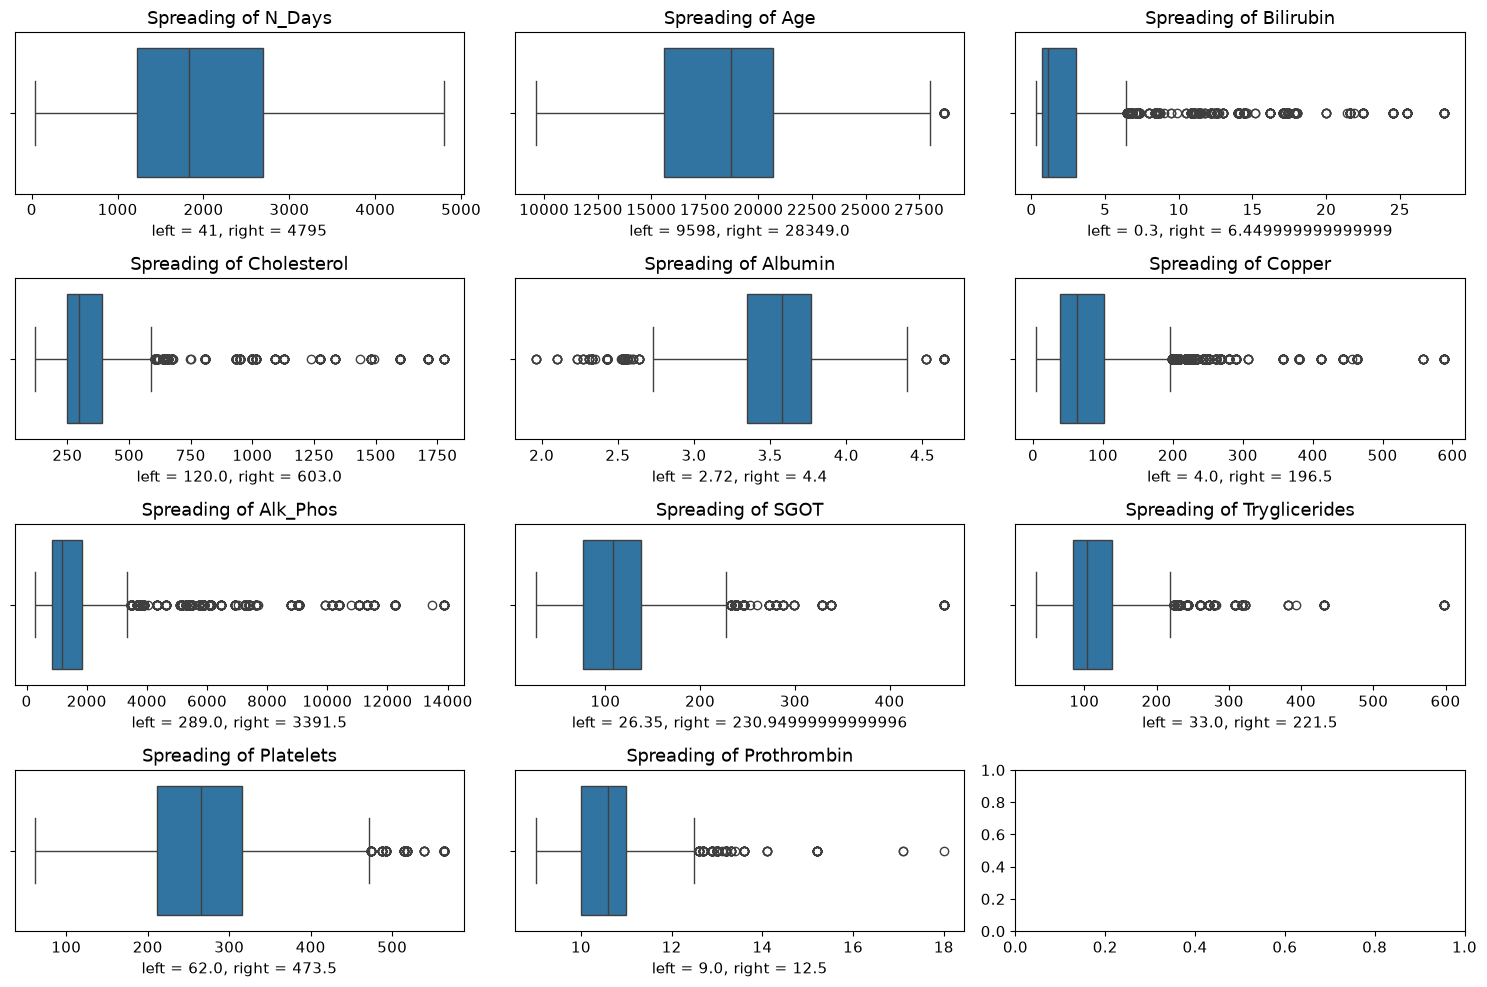

In [40]:
numeric_cols = [
    c for c in train.select_dtypes(include="number").columns
    if c not in {"id", "Stage"}
]

fig, axes = plt.subplots(int(np.ceil(len(numeric_cols)/3)),3, figsize=(15,10))
axes = axes.flatten()
for i, col in enumerate(train[numeric_cols]):
  left, right = get_margins_from_col(train[col])

  sns.boxplot(data=train, x=col, ax=axes[i])
  axes[i].set_title(f'Spreading of {col}')
  axes[i].set_xlabel(f'left = {left}, right = {right}')
plt.tight_layout()
plt.show()

* Во всех биохимических показателях имеются сильно выделяющиеся значения.
* Сильная правая асимметрия у Bilirubin (skew 3,34), Cholesterol (3,68), Alk_Phos (3,20), Copper (2,70), Tryglicerides (2,63): средние завышены относительно медиан, распределения - тяжёлые правые хвосты.
* Age (в записи - дни) распределён почти нормально: центр около 50 лет, диапазон 26–78.
* Albumin - единственный признак с заметной левой асимметрией (−0,56): клинически значим именно левый хвост (низкий альбумин - маркер плохого исхода), а не правый.
* Доля "выбросов" по правилу 1,5×IQR высока - до 10% у Alk_Phos (792 наблюдения) и Bilirubin (789). Но эти значения клинически правдоподобны (Alk_Phos до 13 862, Bilirubin до 28 - соответствует терминальным стадиям ПБХ).
* Platelets и Prothrombin смещены в "нормальный" диапазон с редкими тяжёлыми отклонениями (тромбоциты до 62 - маркер портальной гипертензии, протромбиновое время до 18 сек - коагулопатия): такие хвосты информативнее основной массы и не подлежат "очистке".

Проверяем гипотезу, что отклонения связаны с тяжелым состоянием пациента

In [9]:
test_df = train[numeric_cols].drop(columns=['id', 'N_Days', 'Age'])
results = []

for col in test_df:
  left, right = get_margins_from_col(train[col])
  filtered_df = train[train[col] > right]
  counts =  filtered_df.groupby('Status', observed=False).size().reindex(['C', 'CL', 'D'], fill_value=0)
  counts_sum = counts.sum()

  results.append({
      'Feature': col,
      'Total_patients': counts_sum,
      'C': counts['C'],
      'C_percent': round((counts['C'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'CL': counts['CL'],
      'CL_percent': round((counts['CL'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'D': counts['D'],
      'D_percent': round((counts['D'] / counts_sum * 100), 1) if counts_sum > 0 else 0
  })

results = pd.DataFrame(results)
display(results.sort_values(by='D_percent', ascending=False))


,Feature,Total_patients,C,C_percent,CL,CL_percent,D,D_percent
0,Bilirubin,789,137,17.40,17,2.20,635,80.50
8,Prothrombin,173,32,18.50,2,1.20,139,80.30
3,Copper,655,132,20.20,17,2.60,506,77.30
1,Cholesterol,502,169,33.70,19,3.80,314,62.50
6,Tryglicerides,267,90,33.70,12,4.50,165,61.80
5,SGOT,146,58,39.70,4,2.70,84,57.50
4,Alk_Phos,792,358,45.20,25,3.20,409,51.60
7,Platelets,114,67,58.80,2,1.80,45,39.50
2,Albumin,25,25,100.00,0,0.00,0,0.00


По предварительной оценке уровни биохимических показателей действительно показывают более тяжелое состояние у таких пациентов на основании ответов

Проверим выбросы ниже iQR

In [10]:
test_df = train[numeric_cols].drop(columns=['id', 'N_Days', 'Age'])
results = []

for col in test_df:
  left, right = get_margins_from_col(train[col])
  filtered_df = train[train[col] < left]
  counts =  filtered_df.groupby('Status', observed=False).size().reindex(['C', 'CL', 'D'], fill_value=0)
  counts_sum = counts.sum()

  results.append({
      'Feature': col,
      'Total_patients': counts_sum,
      'C': counts['C'],
      'C_percent': round((counts['C'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'CL': counts['CL'],
      'CL_percent': round((counts['CL'] / counts_sum * 100), 1) if counts_sum > 0 else 0,
      'D': counts['D'],
      'D_percent': round((counts['D'] / counts_sum * 100), 1) if counts_sum > 0 else 0
  })

results = pd.DataFrame(results)
display(results.sort_values(by='D_percent', ascending=False))

,Feature,Total_patients,C,C_percent,CL,CL_percent,D,D_percent
2,Albumin,153,12,7.80,1,0.70,140,91.50
0,Bilirubin,0,0,0.00,0,0.00,0,0.00
1,Cholesterol,0,0,0.00,0,0.00,0,0.00
3,Copper,0,0,0.00,0,0.00,0,0.00
4,Alk_Phos,0,0,0.00,0,0.00,0,0.00
5,SGOT,0,0,0.00,0,0.00,0,0.00
6,Tryglicerides,0,0,0.00,0,0.00,0,0.00
7,Platelets,0,0,0.00,0,0.00,0,0.00
8,Prothrombin,0,0,0.00,0,0.00,0,0.00


Исходя из данных тяжесть состояния отражается низким альбумином.

Чтобы потвердить предположение попробуем найти пациентов с несколькими высокими показателями из превой группы и низким альбумином

In [11]:
train[
    (train['Albumin'] < get_margins_from_col(train['Albumin'])[0])
    & (train['Bilirubin'] > get_margins_from_col(train['Bilirubin'])[1])
    & (train['Prothrombin'] > get_margins_from_col(train['Prothrombin'])[1])
    & (train['Copper'] > get_margins_from_col(train['Copper'])[1])
]

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
3197,3197,1478,D-penicillamine,15177,F,Y,N,Y,Y,17.10,151.00,2.54,207.00,1257.00,119.35,70.00,139.00,12.70,4.00,D
4598,4598,191,D-penicillamine,21483,F,Y,Y,Y,Y,17.90,243.00,2.33,220.00,3196.00,155.00,154.00,165.00,12.60,4.00,D
7642,7642,264,D-penicillamine,20555,F,N,Y,Y,Y,17.40,175.00,2.10,220.00,705.00,338.00,229.00,62.00,12.90,4.00,D


Такие пациенты есть и статус всех мертв.
Дополнительно было запрошено экспертное мнение, из которого подтвердилась гипотеза. При этом экспертом отмечено, что показатели не сильно коррелированы и могут быть в пределах ожидаемого IQR.

C учетом этого данные являются нормальным, а не выбросы.

### 4.2 Анализ дубликатов

In [27]:
train.duplicated().sum()

np.int64(0)

Поскольку id есть у всех и уникально, уберем его и проверим частичные дубликаты

In [13]:
train.drop(columns=['id']).duplicated().sum()

np.int64(0)

Удалим колонку id поскольку она является техническим полем и не несет никакой полезной информации

In [17]:
train_clear = train.drop(columns=['id']).reset_index(drop=True)
train_clear.info()

<class 'pandas.DataFrame'>
RangeIndex: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         7905 non-null   int64  
 1   Drug           7905 non-null   str    
 2   Age            7905 non-null   int64  
 3   Sex            7905 non-null   str    
 4   Ascites        7905 non-null   str    
 5   Hepatomegaly   7905 non-null   str    
 6   Spiders        7905 non-null   str    
 7   Edema          7905 non-null   str    
 8   Bilirubin      7905 non-null   float64
 9   Cholesterol    7905 non-null   float64
 10  Albumin        7905 non-null   float64
 11  Copper         7905 non-null   float64
 12  Alk_Phos       7905 non-null   float64
 13  SGOT           7905 non-null   float64
 14  Tryglicerides  7905 non-null   float64
 15  Platelets      7905 non-null   float64
 16  Prothrombin    7905 non-null   float64
 17  Stage          7905 non-null   float64
 18  Status         7905

Проверка показала, что в датасете присутствует ровно 0 дубликатов. Все наблюдения в таблице уникальны. Технический столбец id не несет аналитической нагрузки, поэтому для дальнейшего исследования мы будем использовать исходный датасет train, просто исключая id на этапе визуализации и расчетов.

## 5. Анализ распределения признаков

### 5.1 Анализ категориальных признаков

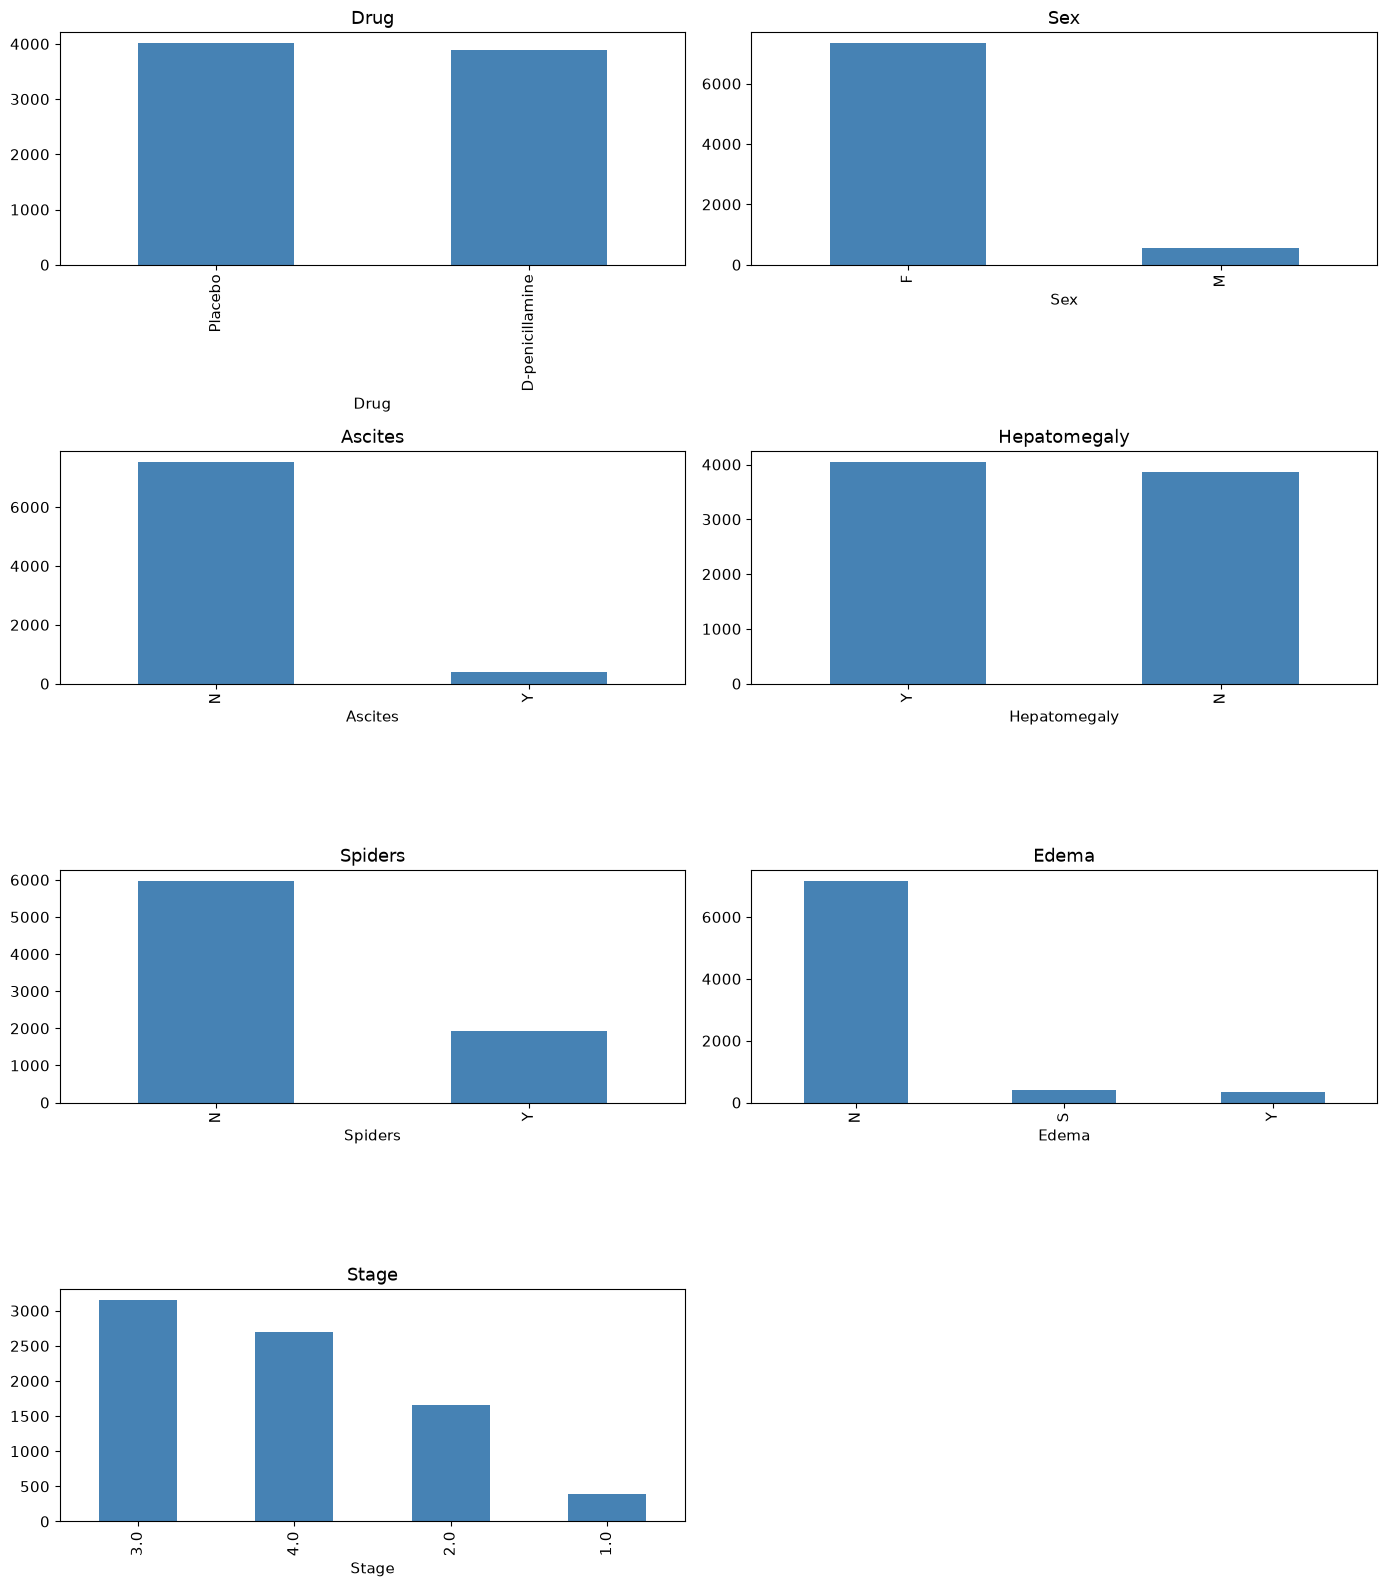

In [28]:
#LABEL = 'Status'
CAT_FEATS = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]
#NUM_FEATS = [x for x in train.columns if x not in CAT_FEATS and x != LABEL and x != 'id']

n = len(CAT_FEATS)
fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(14, 4 * ((n + 1) // 2)))
axes = axes.flatten()
for ax, col in zip(axes, CAT_FEATS):
    train_clear[col].value_counts().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col)
for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

* Drug сбалансирован почти идеально (50,7% placebo vs 49,3% D-penicillamine) - дизайн рандомизированного исследования соблюдён, само по себе лечение не должно быть сильным предиктором. 
* Sex сильно перекошен: 92,8% женщин против 7,2% мужчин. Это типично для ПБХ, но означает, что модель будет слабо обобщаться на мужчин - стратифицировать выборку и не полагаться на Sex как на сильный признак.
* Ascites редкий (только 4,8% "Y") - признак поздней стадии, но именно поэтому потенциально сильно прогностический.
* Hepatomegaly распределён почти поровну (51,1% Y), Spiders - 24,5% Y. Умеренный дисбаланс, кодируются без проблем.
* Edema - три упорядоченных уровня (N 90,6% → S 5,0% → Y 4,4%); корректнее кодировать ординально, а не one-hot.
* Stage - дискретная шкала 1–4 с модой 3 (39,9%); по сути ординальная категория, а не числовой признак.

### 5.2 Анализ числовых признаков

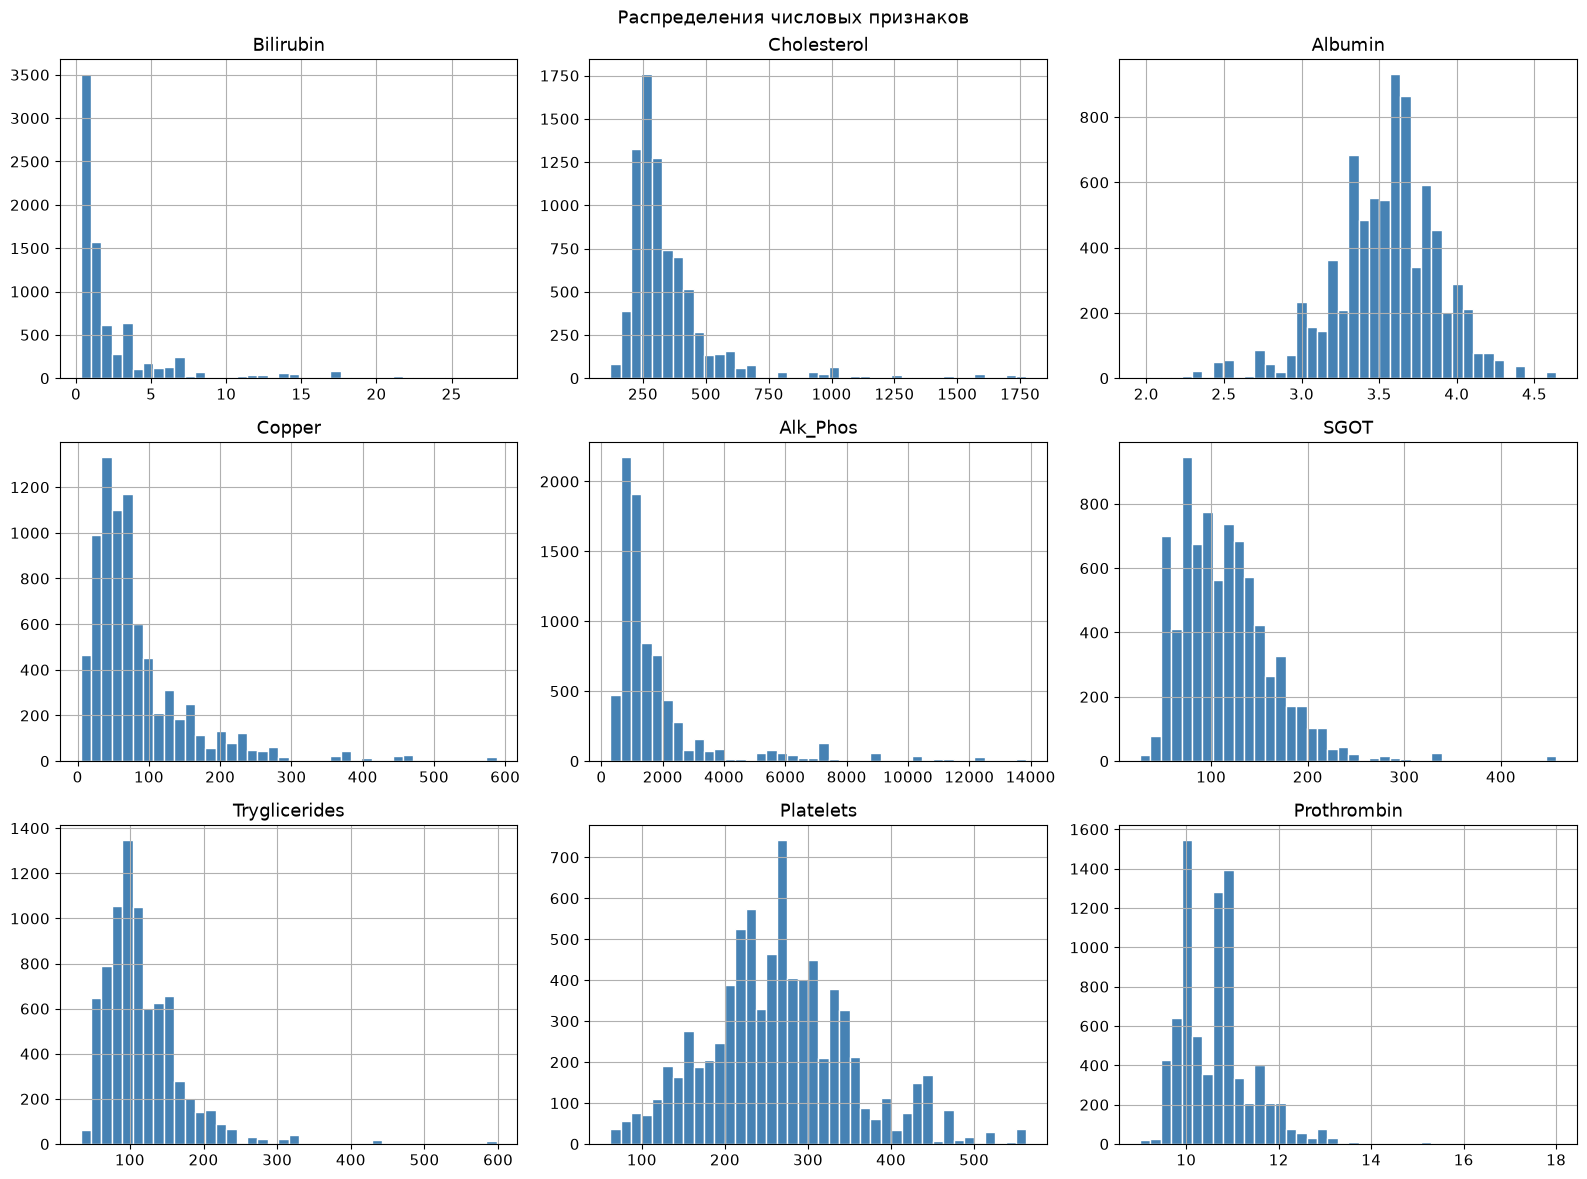

In [29]:
# Собираем числовые колонки из датасета
clean_num_feats = list(train_clear.select_dtypes(include='number').columns)
for col_to_remove in ['id', 'Status', 'Stage', 'Age', 'N_Days']:
    if col_to_remove in clean_num_feats:
        clean_num_feats.remove(col_to_remove)


# Гистограммы 
train_clear[clean_num_feats].hist(bins=40, figsize=(16, 12), color="steelblue", edgecolor="white")
plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.show()


* Сильная правая асимметрия у Bilirubin (skew 3,34), Cholesterol (3,68), Alk_Phos (3,20), Copper (2,70), Tryglicerides (2,63): средние завышены относительно медиан, распределения - тяжёлые правые хвосты.
* Age (в записи - дни) распределён почти нормально: центр около 50 лет, диапазон 26–78.
* Albumin - единственный признак с заметной левой асимметрией (−0,56): клинически значим именно левый хвост (низкий альбумин - маркер плохого исхода), а не правый.
* Доля "выбросов" по правилу 1,5×IQR высока - до 10% у Alk_Phos (792 наблюдения) и Bilirubin (789). Но эти значения клинически правдоподобны (Alk_Phos до 13 862, Bilirubin до 28 - соответствует терминальным стадиям ПБХ).
* Platelets и Prothrombin смещены в "нормальный" диапазон с редкими тяжёлыми отклонениями (тромбоциты до 62 - маркер портальной гипертензии, протромбиновое время до 18 сек - коагулопатия): такие хвосты информативнее основной массы и не подлежат "очистке".


## 6. Исследование баланса целевой переменной Status

### 6.1 Значения целевой переменной и верификация данных

**Цель:** определить численность и доли классов исходов, оценить дисбаланс и сформулировать рекомендации по разбиению данных и оценке моделей.

Источник: Анализ проводится по исходному `train.csv`, до балансировки или иных преобразований. Данные соревнования синтетические: доли характеризуют эту выборку, а не клиническую популяцию.

| Класс | Интерпретация по описанию соревнования |
|---|---|
| C | Пациент жив на момент N_Days; наблюдение цензурировано |
| CL | Пациент жив на момент N_Days после трансплантации печени |
| D | Пациент умер к моменту N_Days |

Класс C не означает выздоровление или гарантированное дальнейшее выживание. Статусы относятся к сроку наблюдения N_Days и не задают единый горизонт прогноза, например один год. 

Проверяем пропуски и допустимые значения. Неожиданные метки не исправляются автоматически: сначала нужно установить их происхождение. При проблемах расчёт останавливается, чтобы не получить неверные доли.

In [30]:
CLASSES = ['C', 'CL', 'D']
target = train_clear['Status']
missing = int(target.isna().sum())
unexpected = target[target.notna() & ~target.isin(CLASSES)]
print('Тип данных:', target.dtype)
print('Уникальные значения:', target.unique().tolist())
print('Пропуски:', missing)
print('Неожиданные метки:', unexpected.unique().tolist())
if len(train) == 0:
    raise ValueError('Выборка пуста.')
if missing or len(unexpected):
    raise ValueError('Сначала разберите пропуски или неожиданные метки Status.')
if not set(CLASSES).issubset(set(target)):
    raise ValueError('Один из трёх ожидаемых классов отсутствует.')
print('Проверка пройдена: все статусы заполнены и соответствуют описанию.')

Тип данных: str
Уникальные значения: ['D', 'C', 'CL']
Пропуски: 0
Неожиданные метки: []
Проверка пройдена: все статусы заполнены и соответствуют описанию.


### 6.2 Численность и доли классов
Доля класса = число его наблюдений / общее число наблюдений × 100%. Порядок классов фиксирован для удобного сравнения.

In [31]:
counts = target.value_counts().reindex(CLASSES, fill_value=0)
shares = counts / len(train)
summary = pd.DataFrame({'Количество': counts, 'Доля, %': shares * 100})
summary.index.name = 'Status'
print(summary.to_string())
print(f'Проверка суммы: {counts.sum()} наблюдений, {shares.sum():.0%} выборки.')

        Количество  Доля, %
Status                     
C             4965    62.81
CL             275     3.48
D             2665    33.71
Проверка суммы: 7905 наблюдений, 100% выборки.


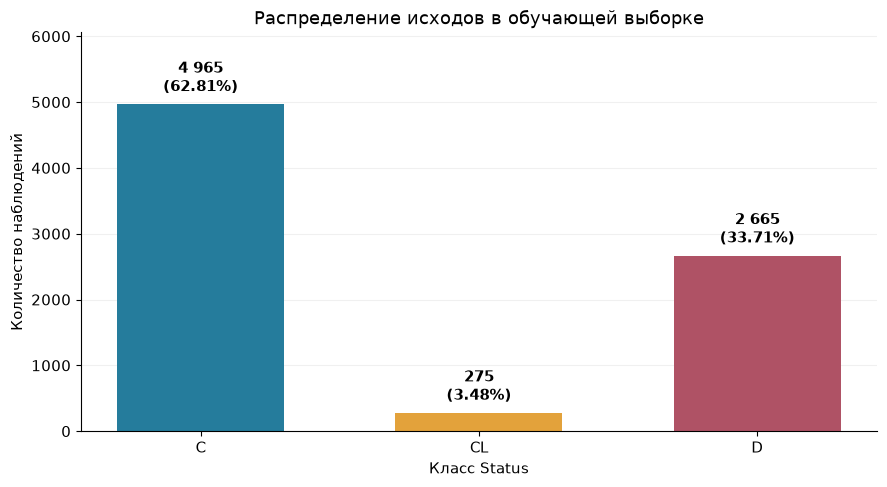

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(CLASSES, counts.values, color=['#257C9C', '#E3A23B', '#AF5265'], width=0.6)
for bar, count, share in zip(bars, counts.values, shares.values):
    label = f'{count:,}'.replace(',', ' ') + f'\n({share:.2%})'
    ax.text(bar.get_x() + bar.get_width()/2, count + counts.max()*0.025,
            label, ha='center', va='bottom', fontweight='bold')
ax.set(title='Распределение исходов в обучающей выборке',
       xlabel='Класс Status', ylabel='Количество наблюдений', ylim=(0, counts.max()*1.22))
ax.spines[['top', 'right']].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.18)
fig.tight_layout()
plt.show()

### 6.3 Оценка дисбаланса
Отношение численности самого частого класса к самому редкому: **IR = n_max / n_min**. Дополнительно учитываем абсолютное число наблюдений редкого класса. Единого универсального порога «сильного дисбаланса» для всех задач нет.

Accuracy постоянного прогноза наиболее частого класса показывает, почему общей доли правильных ответов недостаточно. Это описательный ориентир на всей выборке, а не проверенная на отложенных данных модель.

In [33]:
majority = counts.idxmax()
minority = counts.idxmin()
imbalance_ratio = counts.max() / counts.min()
print(f'Самый частый класс: {majority} — {counts.max()} ({shares[majority]:.2%}).')
print(f'Самый редкий класс: {minority} — {counts.min()} ({shares[minority]:.2%}).')
print(f'Отношение {majority}/{minority}: {imbalance_ratio:.2f}:1.')
print(f'Отношение D/CL: {counts["D"] / counts["CL"]:.2f}:1.')
print(f'Accuracy постоянного прогноза {majority}: {shares[majority]:.2%}.')

Самый частый класс: C — 4965 (62.81%).
Самый редкий класс: CL — 275 (3.48%).
Отношение C/CL: 18.05:1.
Отношение D/CL: 9.69:1.
Accuracy постоянного прогноза C: 62.81%.


### 6.4 Демонстрация стратифицированного разбиения 80/20
Фиксируем random_state=42. Стратификация сохраняет близкие доли классов, но не устраняет дисбаланс. Отложенная часть выделяется из train.csv; конкурсный test.csv не используется для локальной оценки качества.

In [34]:
from sklearn.model_selection import train_test_split

train_idx, valid_idx = train_test_split(
    train.index, test_size=0.20, random_state=42, stratify=target
)
train_counts = target.loc[train_idx].value_counts().reindex(CLASSES, fill_value=0)
valid_counts = target.loc[valid_idx].value_counts().reindex(CLASSES, fill_value=0)
split_summary = pd.DataFrame({
    'Всего': counts,
    'Обучение, n': train_counts,
    'Обучение, %': train_counts / len(train_idx) * 100,
    'Валидация, n': valid_counts,
    'Валидация, %': valid_counts / len(valid_idx) * 100,
})
print(split_summary.to_string())
print(f'Обучение: {len(train_idx)}; валидация: {len(valid_idx)}.')
print('Данные не изменены; разбиение показано для иллюстрации.')

        Всего  Обучение, n  Обучение, %  Валидация, n  Валидация, %
Status                                                             
C        4965         3972        62.81           993         62.81
CL        275          220         3.48            55          3.48
D        2665         2132        33.71           533         33.71
Обучение: 6324; валидация: 1581.
Данные не изменены; разбиение показано для иллюстрации.


### 6.5 Представленность классов при пятифолдовой кросс-валидации
Демонстрация на всей исходной обучающей выборке.

In [35]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_counts = []
for fold, (_, fold_valid_idx) in enumerate(cv.split(train, target), start=1):
    current = target.iloc[fold_valid_idx].value_counts().reindex(CLASSES, fill_value=0)
    fold_counts.append({'Фолд': fold, **current.to_dict()})
print(pd.DataFrame(fold_counts).set_index('Фолд').to_string())

        C  CL    D
Фолд              
1     993  55  533
2     993  55  533
3     993  55  533
4     993  55  533
5     993  55  533


### 6.6 Вывод по рассчитанным данным

In [36]:
print(f'В обучающей выборке {len(train)} наблюдений. '
      f'Класс C: {counts["C"]} ({shares["C"]:.2%}); '
      f'CL: {counts["CL"]} ({shares["CL"]:.2%}); '
      f'D: {counts["D"]} ({shares["D"]:.2%}).')
print(f'Распределение неравномерно: класс {majority} встречается '
      f'в {imbalance_ratio:.2f} раза чаще класса {minority}. '
      'Дисбаланс следует учитывать при разбиении и оценке моделей.')
print(f'В демонстрационном разбиении в валидации остаётся '
      f'{valid_counts[minority]} наблюдений самого редкого класса. '
      'Небольшое число ошибок может заметно менять его метрики.')

В обучающей выборке 7905 наблюдений. Класс C: 4965 (62.81%); CL: 275 (3.48%); D: 2665 (33.71%).
Распределение неравномерно: класс C встречается в 18.05 раза чаще класса CL. Дисбаланс следует учитывать при разбиении и оценке моделей.
В демонстрационном разбиении в валидации остаётся 55 наблюдений самого редкого класса. Небольшое число ошибок может заметно менять его метрики.


## 7. Двумерный анализ

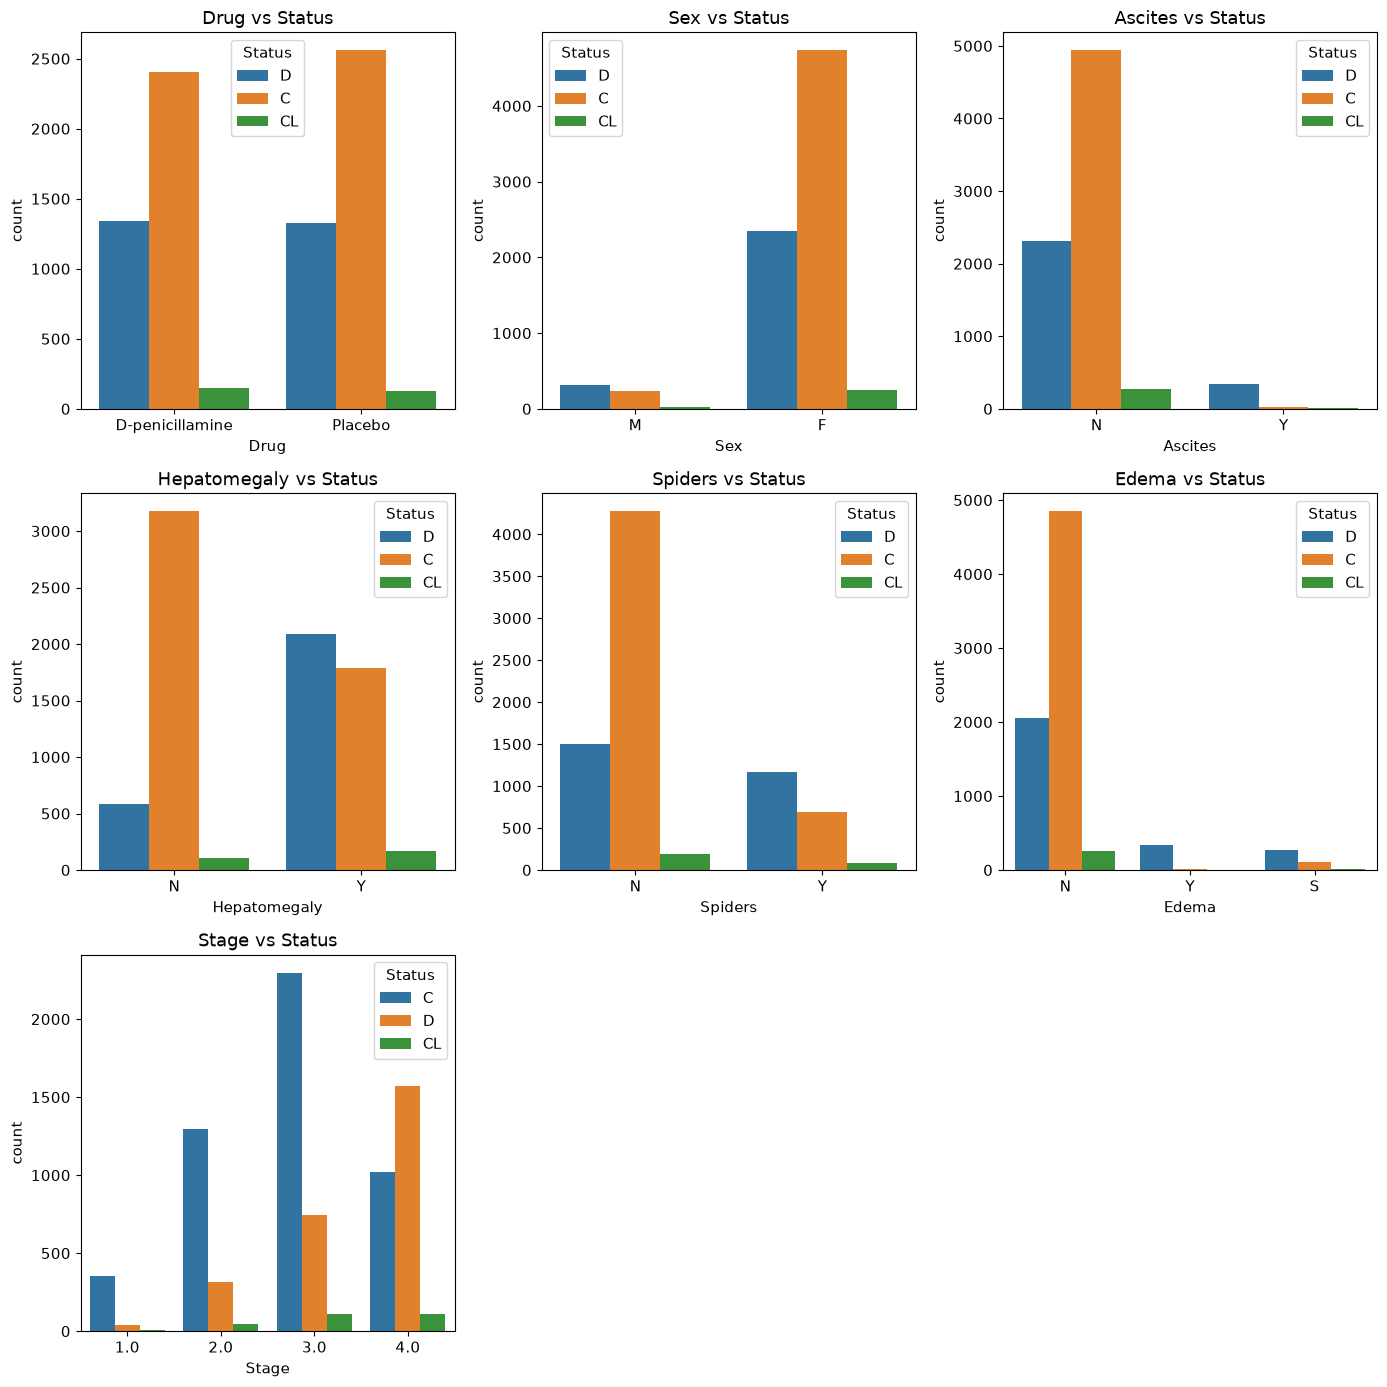

In [ ]:
LABEL = 'Status'

plt.figure(figsize=(14, len(CAT_FEATS) * 2))
for i, col in enumerate(CAT_FEATS):
    plt.subplot(int(np.ceil(len(CAT_FEATS) / 3)), 3, i + 1)
    sns.countplot(x=col, hue=LABEL, data=train_clear)
    plt.title(f"{col} vs {LABEL}")
    plt.tight_layout()
plt.show()

* У мужчин медианный билирубин 2,1 против 1,1 у женщин (p = 7×10⁻³¹) - то есть мужчины приходят к врачу с более запущенной болезнью.Sex - не самостоятельный фактор риска, а маркер более тяжёлого дебюта; при моделировании это проявится как реальный, но косвенный вклад.
* Drug: p = 0,053, на границе значимости, V = 0,03. Эффекта лечения нет - но не потому, что его «не видно», а потому, что его действительно нет (рандомизация чистая). Признак можно исключать.

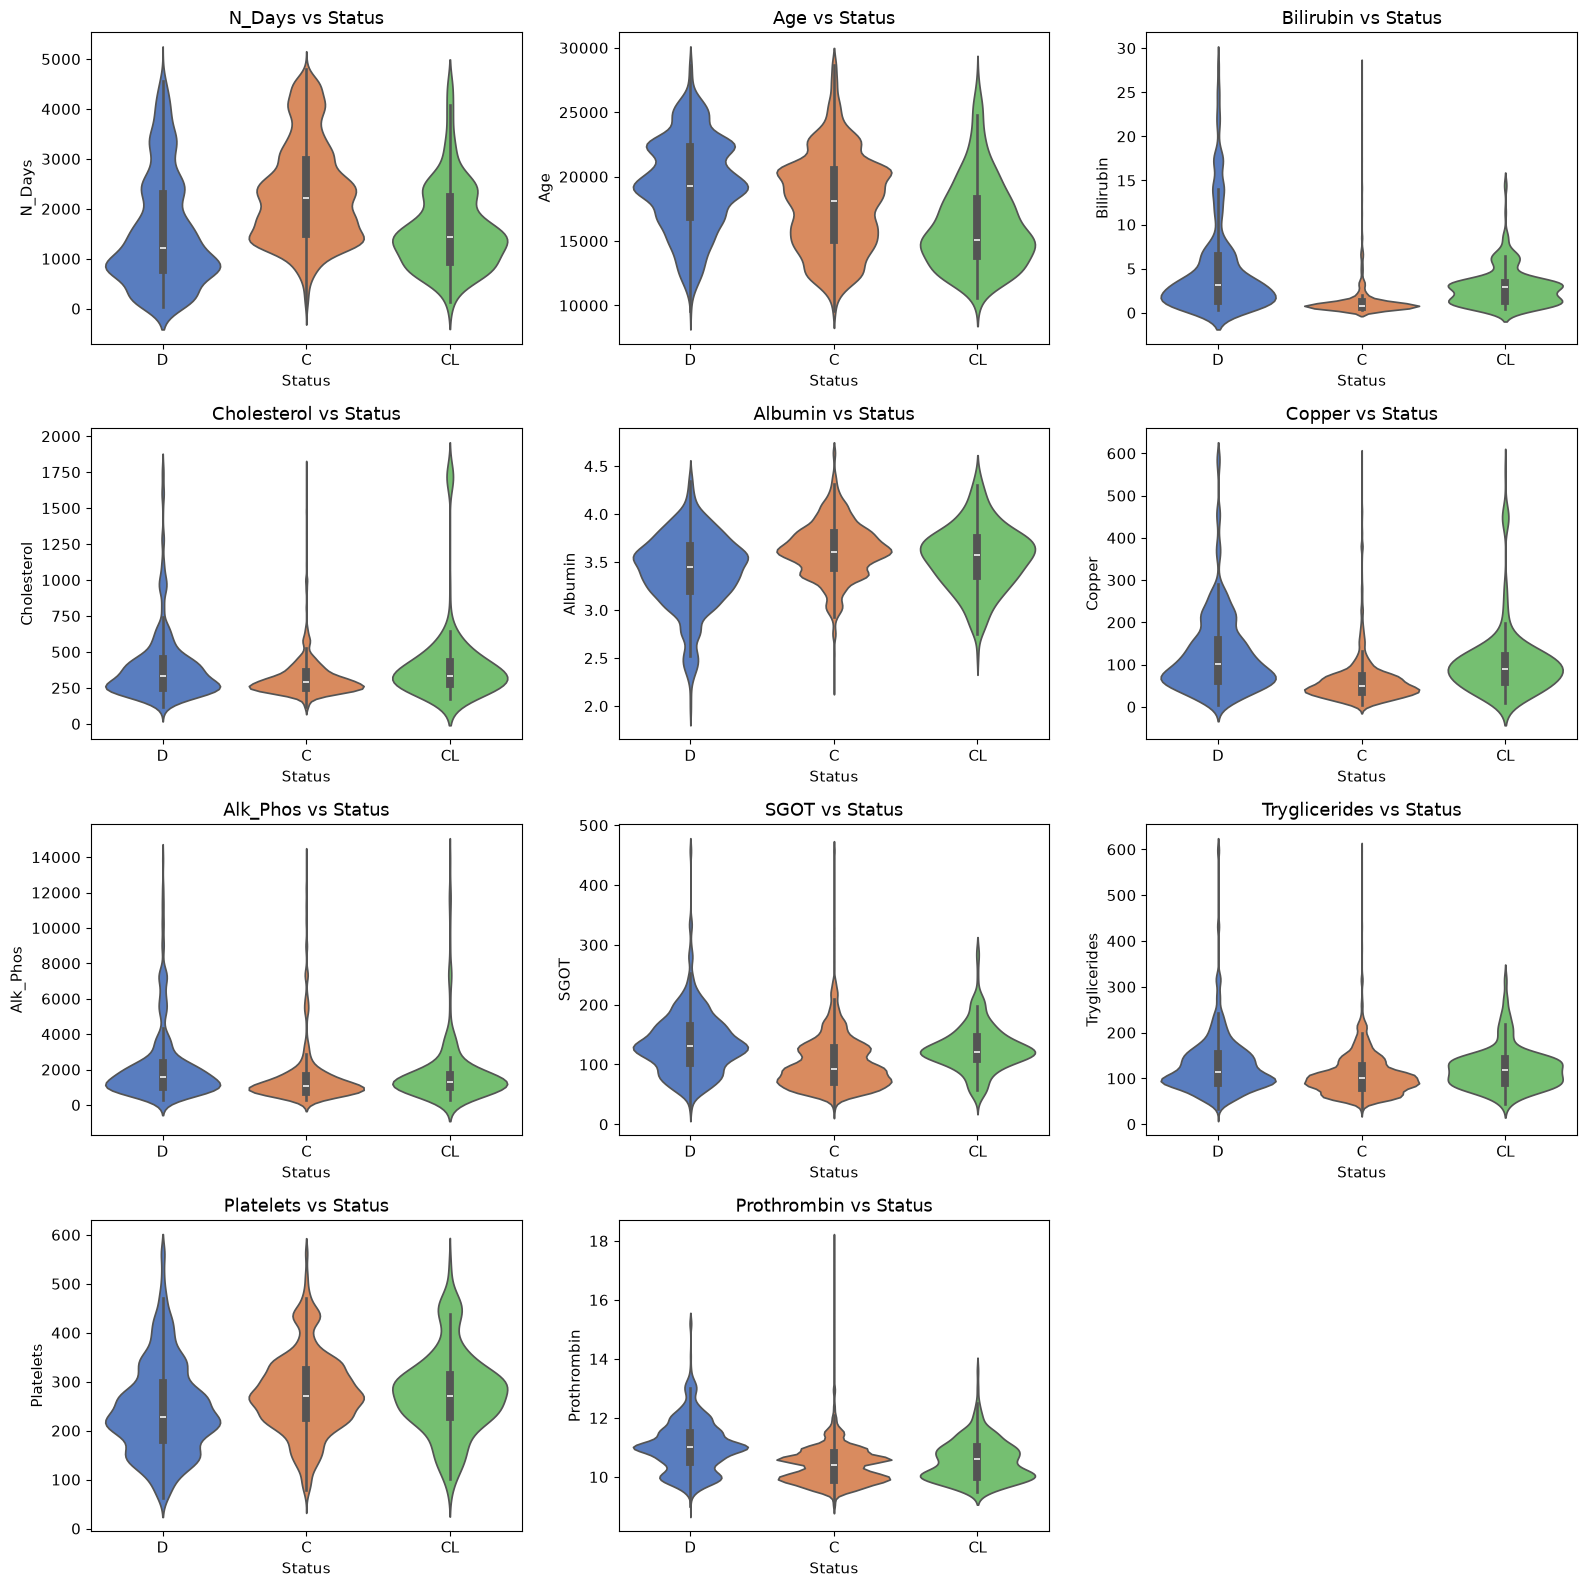

In [41]:
'''
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for i, ax in enumerate(axes.flatten()[:len(clean_num_feats)]):
    sns.violinplot(x=LABEL, y=clean_num_feats[i], data=train_clear, ax=ax, hue=LABEL, palette="muted", legend=False)
    ax.set_title(f"{clean_num_feats[i]} vs {LABEL}")

plt.tight_layout()
plt.show()
'''

n = len(clean_num_feats)
ncols = 3
nrows = int(np.ceil(n / ncols)) 

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))

axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, clean_num_feats):
    sns.violinplot(x="Status", y=col, data=train_clear,
                   ax=ax, hue="Status", palette="muted", legend=False)
    ax.set_title(f"{col} vs Status")

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

* Prothrombin имеет пороговый характер (~10,7 сек) - деревьям это на руку, линейным моделям лучше дать бинаризованный флаг "Prothrombin > 10,7".
* Билирубин важнее стадии: Stage 1 + высокий билирубин опаснее Stage 4 + низкий. Взаимодействие Stage × Bilirubin - кандидат на явную фичу в модели.
* Sex - косвенный маркер тяжести дебюта, эффект через билирубин; оставляем признак, но интерпретируем аккуратно.
* Drug не связан с исходом (p = 0,05, V = 0,03) - в модель не нужен.
* Симптомный блок комбинируется: Edema=Y + Ascites=Y - почти приговор (98,8%). Уже на EDA видно, что простое дерево правил уложится в приличное качество.

## 8. Корреляционный анализ

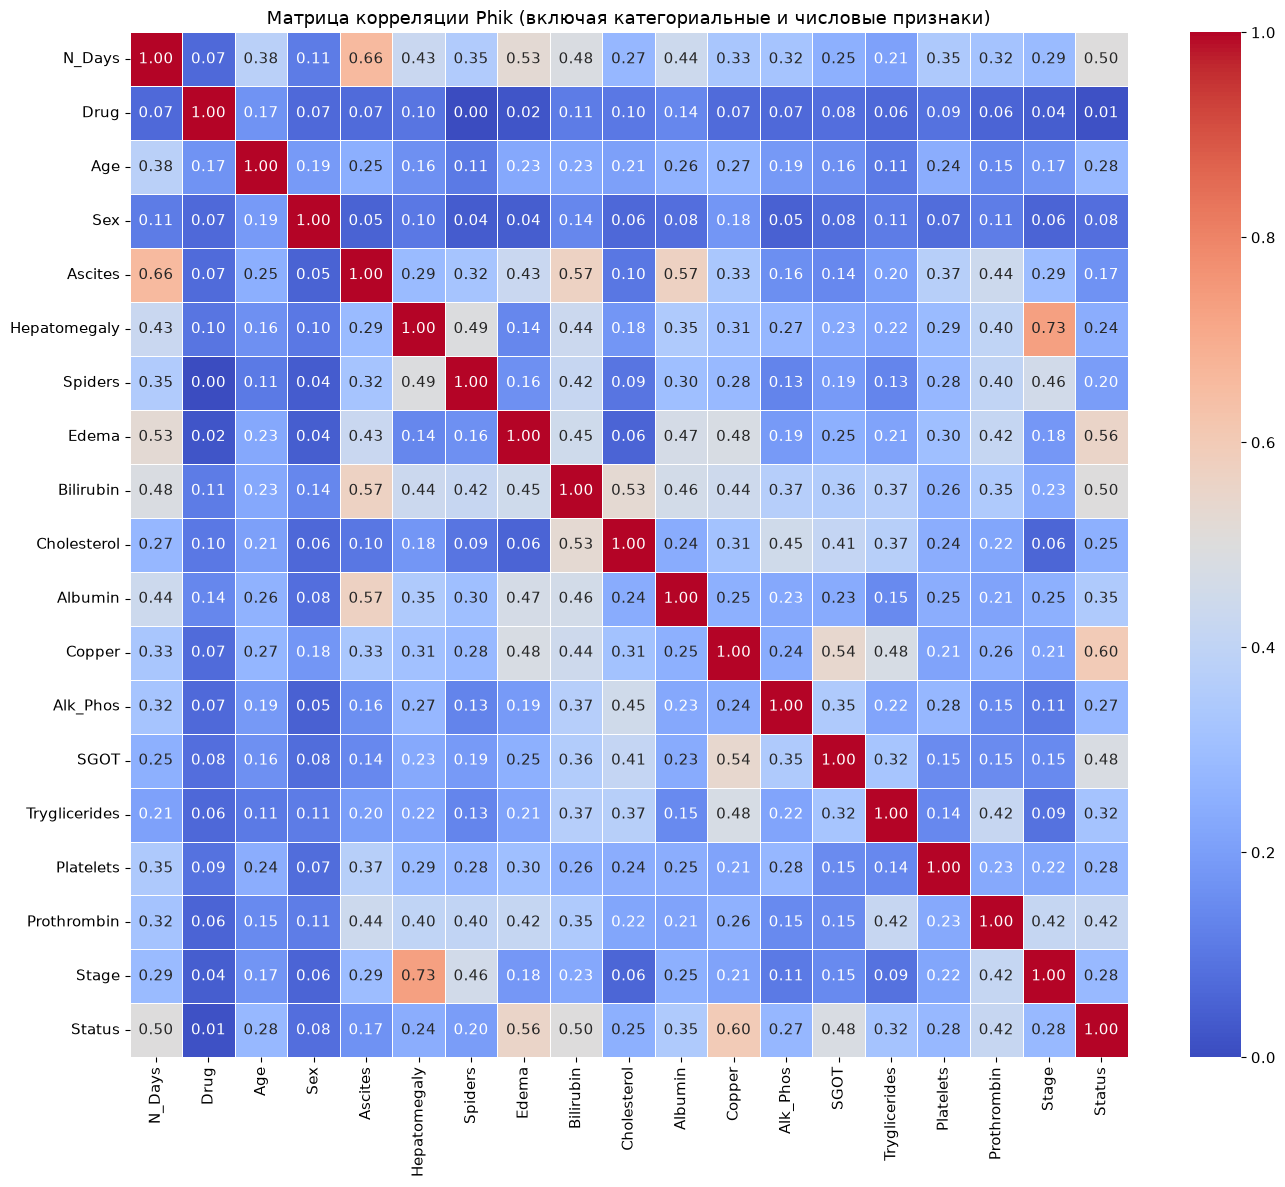

In [39]:
cols_for_corr = [c for c in train_clear.columns if c != 'id']
clean_num_feats = list(train_clear.select_dtypes(include='number').columns)
for col_to_remove in ['id', 'Status', 'Stage']:
    if col_to_remove in clean_num_feats:
        clean_num_feats.remove(col_to_remove)

phik_matrix = phik.phik_matrix(train_clear[cols_for_corr], interval_cols=clean_num_feats)

plt.figure(figsize=(14, 12))
sns.heatmap(phik_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1, linewidths=0.5)
plt.title("Матрица корреляции Phik (включая категориальные и числовые признаки)")
plt.tight_layout()
plt.show()

* Сильной корреляции между признаками нет, заметна только средняя положительная связь у билирубина с медью и средняя отрицательная с альбумином.
* Бинарные категориальные признаки Sex, Drug, Ascites, Spiders, Hepatomegaly перед моделированием нужно преобразовать в 0 и 1.
* Числовой формат для Edema может запутать линейные модели, поэтому для них лучше сделать One-Hot Encoding (столбцы Edema_N, Edema_S, Edema_Y), а для деревьев решений и бустингов можно оставить всё как есть.
* С признаком Stage ситуация аналогичная: стадии отражают качество, а не количество, поэтому для линейных моделей применяем OHE, а для бустингов сохраняем исходные цифры.


## 9. Гипотезы и инсайты для этапа машинного обучения

### 9.1 Анализ целевой переменной и качества данных
Выявлен выраженный дисбаланс классов: C встречается в 18,05 раза чаще CL (62,81% против 3,48%). Для сохранения пропорций классов при обучении следует использовать стратифицированную кросс-валидацию (StratifiedKFold, 5 фолдов). Также стоит проверить взвешивание классов (class_weight='balanced' или аналогичный механизм в выбранной модели).

Полных дубликатов в данных не обнаружено, поэтому удаление строк не требуется. Базовая Accuracy при прогнозе только наиболее частого класса составляет 62,81%, однако эта метрика не отражает качество распознавания редких классов. Для оценки моделей следует использовать multiclass log loss.

### 9.2 Анализ распределений и выбросов
Bilirubin, Cholesterol, Alk_Phos, Copper и Triglycerides имеют выраженную правую асимметрию. Экстремальные значения могут отражать реальные особенности состояния пациентов, поэтому удалять их автоматически не следует. Для линейных моделей и нейросетей можно проверить логарифмическое преобразование np.log1p.

Albumin имеет левую асимметрию (-0,56). Среди пациентов со значениями ниже нижней границы IQR доля летальных исходов составляет 91,5%. Это указывает на потенциальную информативность признака при прогнозировании исхода.

### 9.3 Категориальные признаки и кодирование
Категории Drug распределены практически поровну (50,7% и 49,3%), а связь с целевой переменной по коэффициенту \(\Phi_K\) близка к нулю (0,01). Полезность признака стоит проверить сравнением моделей с ним и без него.

Stage и Edema имеют упорядоченные категории. Для линейных моделей можно проверить One-Hot Encoding, а для градиентного бустинга — способы кодирования, поддерживаемые конкретной библиотекой.

### 9.4 Генерация признаков
Сочетание Edema == 'Y' и Ascites == 'Y' связано с долей летальных исходов 98,8%. Стоит проверить размер этой подгруппы и информативность бинарного признака edema_ascites_combination.

Уровень Bilirubin может содержать дополнительную информацию о тяжести состояния, не отражённую в Stage. Можно проверить взаимодействие этих признаков, например Bilirubin * Stage.

### 9.5 Интегральные медицинские шкалы
Альбумин, билирубин и протромбиновое время отражают разные аспекты функции печени. В качестве дополнительных признаков можно рассмотреть клинические показатели ALBI_score и Mayo_risk_score. Для их расчёта необходимо проверить единицы измерения и наличие всех необходимых переменных.

### 9.6 Методологические ограничения
N_Days связан с определением целевой переменной Status. Для конкурсной задачи Kaggle его использование допустимо в рамках заданной постановки. Однако для клинического прогноза на момент первичного обращения этот признак необходимо исключить, поскольку он содержит информацию о будущем периоде наблюдения и создаёт риск утечки данных (data leakage).